In [2]:
# ===================== PERSONAL SETTINGS (first cell, as required) =====================
REG_NO = "011"                                         # y registration number

SEED      = int(REG_NO[-2:])                           # last two digits -> 011 gives 11
HOG_CELL  = 8 if int(REG_NO[-1]) % 2 == 0 else 16      # last digit even -> 8x8, odd -> 16x16
SIFT_GRID = 4 if int(REG_NO[-1]) <= 4 else 6           # last digit 0-4 -> 4x4 grid, 5-9 -> 6x6 grid

print(f"Registration number : {REG_NO}")
print(f"Random seed         : {SEED}")
print(f"HOG cell size       : {HOG_CELL} x {HOG_CELL}")
print(f"SIFT grid size      : {SIFT_GRID} x {SIFT_GRID}  ->  {SIFT_GRID ** 2} keypoints")


Registration number : 011
Random seed         : 11
HOG cell size       : 16 x 16
SIFT grid size      : 4 x 4  ->  16 keypoints


# Lab Mid Exam — HOG vs SIFT on Blood-Cell Images
**Task:** build two classical pipelines, **HOG + SVM** and **SIFT + SVM**, and find out which one is more reliable when images are rotated or noisy.

**Fixed settings:** BloodMNIST (size 64) · classes eosinophil (1), monocyte (5), neutrophil (6), platelet (7) · 100 train / 30 validation / 30 test images per class (chosen with my seed) ·
grayscale, resized to 128×128 · HOG: 9 orientations, 2×2 cells per block · classifier `LinearSVC`, C ∈ {0.1, 1, 10} chosen on the **validation** set · rotation test 20° · noise test σ = 0.05.

**Rule followed in this notebook:** the validation set is used to choose C; the **test set is touched only in Q4**.

In [3]:
# Install the two libraries only if they are missing (works in Colab, Kaggle and local Jupyter)
import importlib, subprocess, sys
for pkg in ["medmnist", "kagglehub"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
print("medmnist and kagglehub are ready")


medmnist and kagglehub are ready


In [4]:
import os, random, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

random.seed(SEED)
np.random.seed(SEED)

OUT = "labmid_outputs"                       # figures + results file are saved here
os.makedirs(OUT, exist_ok=True)
R = {}                                       # collects results for the final results.md file


def save_show(fig, name):
    fig.savefig(os.path.join(OUT, name), dpi=130, bbox_inches="tight")
    plt.show()

print("numpy", np.__version__, "| opencv", cv2.__version__)


numpy 2.1.3 | opencv 5.0.0


# Q1. Data setup (3 marks)
Load BloodMNIST (size 64), keep the four classes, and take 100 / 30 / 30 images per class for train / validation / test.
The images are chosen **randomly with my seed** (`np.random.RandomState(SEED)`), so the same subset is obtained every time the notebook is run.

In [5]:
DATA_ROOT = "medmnist_data"
os.makedirs(DATA_ROOT, exist_ok=True)

DATA_SOURCE = "auto"     # "auto": official MedMNIST (size 64) first, then the Kaggle copy | or force "medmnist" / "kaggle"
CLASS_IDS   = [1, 5, 6, 7]                                       # original BloodMNIST label ids
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}
SPLITS      = ("train", "val", "test")


def load_from_medmnist():
    from medmnist import BloodMNIST, INFO
    for cid, name in zip(CLASS_IDS, CLASS_NAMES):                # the label ids really mean what the exam says
        assert INFO["bloodmnist"]["label"][str(cid)].startswith(name), (cid, name)
    out = {}
    for split in SPLITS:
        ds = BloodMNIST(split=split, download=True, size=64, root=DATA_ROOT)
        out[split] = (np.asarray(ds.imgs), np.asarray(ds.labels).ravel())
    return out


def load_from_kaggle():
    import kagglehub
    root = kagglehub.dataset_download("flyt007/bloodmnist")
    print("Kaggle dataset path:", root)
    npzs = [os.path.join(dp, f) for dp, _, fs in os.walk(root) for f in fs if f.lower().endswith(".npz")]
    npzs.sort(key=lambda f: ("64" not in os.path.basename(f), "blood" not in os.path.basename(f).lower()))
    keys = [f"{s}_{k}" for s in SPLITS for k in ("images", "labels")]
    for f in npzs:
        d = np.load(f)
        if all(k in d.files for k in keys):
            print("Using file:", os.path.relpath(f, root))
            return {s: (d[f"{s}_images"], d[f"{s}_labels"].ravel()) for s in SPLITS}
    raise RuntimeError("no MedMNIST-style .npz file found in the Kaggle download")


FULL, SOURCE = None, None
for src_name in {"auto": ["medmnist", "kaggle"], "medmnist": ["medmnist"], "kaggle": ["kaggle"]}[DATA_SOURCE]:
    try:
        FULL = {"medmnist": load_from_medmnist, "kaggle": load_from_kaggle}[src_name]()
        SOURCE = src_name
        break
    except Exception as e:
        print(f"[{src_name}] could not load the data -> {type(e).__name__}: {e}")
if FULL is None:
    raise RuntimeError("BloodMNIST could not be loaded from medmnist or Kaggle - check that Internet is ON.")

NATIVE = FULL["train"][0].shape[1]
print(f"\nData source: {SOURCE} | native image size: {NATIVE} x {NATIVE}")
if NATIVE != 64:
    print(f"NOTE: this copy of BloodMNIST is {NATIVE}x{NATIVE}, not 64x64. Every image is resized to 128x128 anyway (next section), "
          "but mention this in your report.")

rng = np.random.RandomState(SEED)                                 # ALL random choices of the subset use this seed


def take_subset(split):
    imgs, labels = FULL[split]
    print(f"full '{split}' split: images {imgs.shape}")
    X_parts, y_parts = [], []
    for new_label, cid in enumerate(CLASS_IDS):
        idx = np.where(labels == cid)[0]
        chosen = rng.choice(idx, N_PER_CLASS[split], replace=False)   # random, without replacement, seeded
        X_parts.append(imgs[chosen])
        y_parts.append(np.full(len(chosen), new_label))
    return np.concatenate(X_parts), np.concatenate(y_parts)


X_tr, y_tr = take_subset("train")
X_va, y_va = take_subset("val")
X_te, y_te = take_subset("test")

rows = []
for split, X, y in [("train", X_tr, y_tr), ("validation", X_va, y_va), ("test", X_te, y_te)]:
    row = {"split": split, "X shape": X.shape, "y shape": y.shape}
    row.update({name: int((y == k).sum()) for k, name in enumerate(CLASS_NAMES)})
    rows.append(row)
counts_df = pd.DataFrame(rows)
R["q1_counts"] = counts_df
print()
display(counts_df)
assert len(X_tr) == 400 and len(X_va) == 120 and len(X_te) == 120


100%|██████████| 156M/156M [01:07<00:00, 2.32MB/s]



Data source: medmnist | native image size: 64 x 64
full 'train' split: images (11959, 64, 64, 3)
full 'val' split: images (1712, 64, 64, 3)
full 'test' split: images (3421, 64, 64, 3)



,split,X shape,y shape,eosinophil,monocyte,neutrophil,platelet
0,train,"(400, 64, 64, 3)","(400,)",100,100,100,100
1,validation,"(120, 64, 64, 3)","(120,)",30,30,30,30
2,test,"(120, 64, 64, 3)","(120,)",30,30,30,30


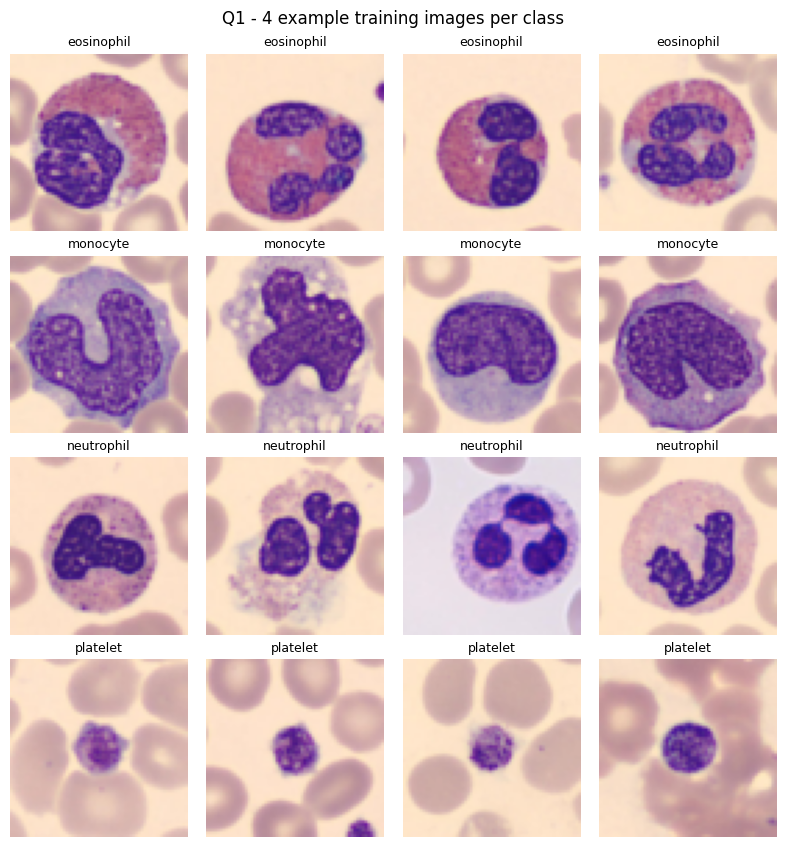

In [6]:
# one grid with 4 example images per class (original colour images)
fig, axes = plt.subplots(4, 4, figsize=(8, 8.6))
for r, name in enumerate(CLASS_NAMES):
    for c, i in enumerate(np.where(y_tr == r)[0][:4]):
        axes[r, c].imshow(X_tr[i]); axes[r, c].axis("off"); axes[r, c].set_title(name, fontsize=9)
fig.suptitle("Q1 - 4 example training images per class")
plt.tight_layout()
save_show(fig, "q1_examples.png")


### Image preparation (grayscale + resize to 128 × 128)
Every image is converted to grayscale and resized to 128 × 128 (`uint8`). Both models use exactly these prepared images.

prepared train/val/test: (400, 128, 128) (120, 128, 128) (120, 128, 128) uint8


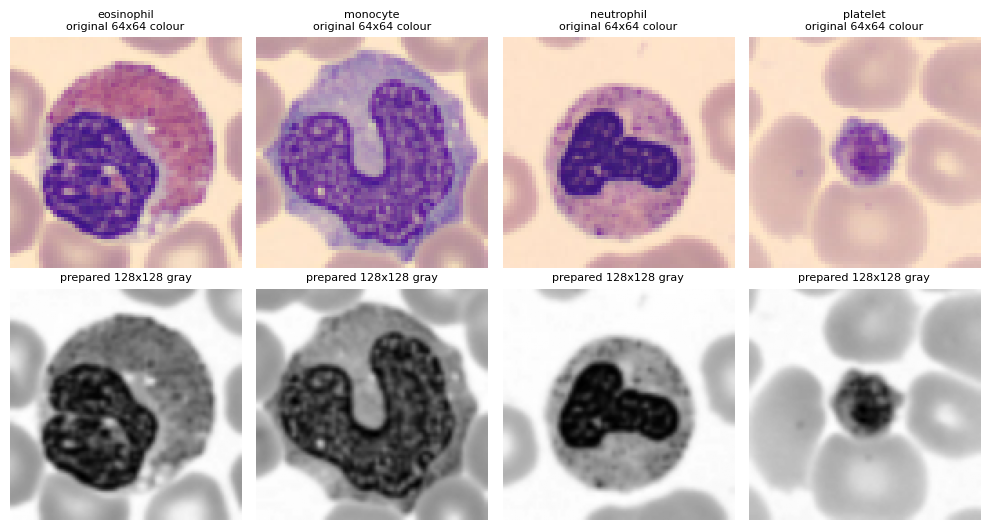

In [7]:
def prepare(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY) if img_rgb.ndim == 3 else img_rgb   # grayscale
    return cv2.resize(gray, (128, 128), interpolation=cv2.INTER_LINEAR)      # 128 x 128, still uint8


G_tr = np.stack([prepare(im) for im in X_tr])
G_va = np.stack([prepare(im) for im in X_va])
G_te = np.stack([prepare(im) for im in X_te])      # prepared now, but NOT used before Q4
print("prepared train/val/test:", G_tr.shape, G_va.shape, G_te.shape, G_tr.dtype)

fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for k, name in enumerate(CLASS_NAMES):
    i = np.where(y_tr == k)[0][0]
    axes[0, k].imshow(X_tr[i]); axes[0, k].set_title(f"{name}\noriginal {NATIVE}x{NATIVE} colour", fontsize=8)
    axes[1, k].imshow(G_tr[i], cmap="gray"); axes[1, k].set_title("prepared 128x128 gray", fontsize=8)
    axes[0, k].axis("off"); axes[1, k].axis("off")
plt.tight_layout()
save_show(fig, "q1_prepared.png")


# Q2. HOG + SVM (6 marks)

## Q2 (a) HOG features and feature length
HOG settings: 9 orientations, **16 × 16 pixels per cell** (from my registration number), 2 × 2 cells per block, L2-Hys block normalisation.

In [8]:
def hog_vec(img):
    return hog(img, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)


def hog_matrix(images):
    return np.array([hog_vec(im) for im in images], dtype=np.float32)


H_tr = hog_matrix(G_tr)
H_va = hog_matrix(G_va)

hog_len = H_tr.shape[1]
cells_per_side  = 128 // HOG_CELL
blocks_per_side = cells_per_side - 2 + 1
formula_len     = blocks_per_side * blocks_per_side * 2 * 2 * 9

print("HOG feature matrix  train:", H_tr.shape, " validation:", H_va.shape)
print("HOG feature length (from the code)    :", hog_len)
print(f"Hand formula: ({cells_per_side} - 2 + 1)^2 blocks x (2 x 2 x 9) = "
      f"{blocks_per_side ** 2} x 36 = {formula_len}")
assert hog_len == formula_len, "feature length does not match the hand calculation!"
R["hog_len"] = hog_len


HOG feature matrix  train: (400, 1764)  validation: (120, 1764)
HOG feature length (from the code)    : 1764
Hand formula: (8 - 2 + 1)^2 blocks x (2 x 2 x 9) = 49 x 36 = 1764


**Hand calculation of the HOG feature length** (image 128 × 128, cell 16 × 16, 2 × 2 cells per block, 9 orientations):

1. Cells per side = 128 / 16 = **8** → 8 × 8 = 64 cells.
2. Blocks slide one cell at a time, so blocks per side = 8 − 2 + 1 = **7** → 7 × 7 = **49 blocks**.
3. Each block contains 2 × 2 = 4 cells, and each cell has a 9-bin histogram → 4 × 9 = **36 numbers per block**.
4. Feature length = 49 blocks × 36 = **1764**.

(General formula: `((128/cell) − 1)² × 2 × 2 × 9`; for cell 8 it would be 15² × 36 = 8100.)

## Q2 (b) HOG picture for one image from each class

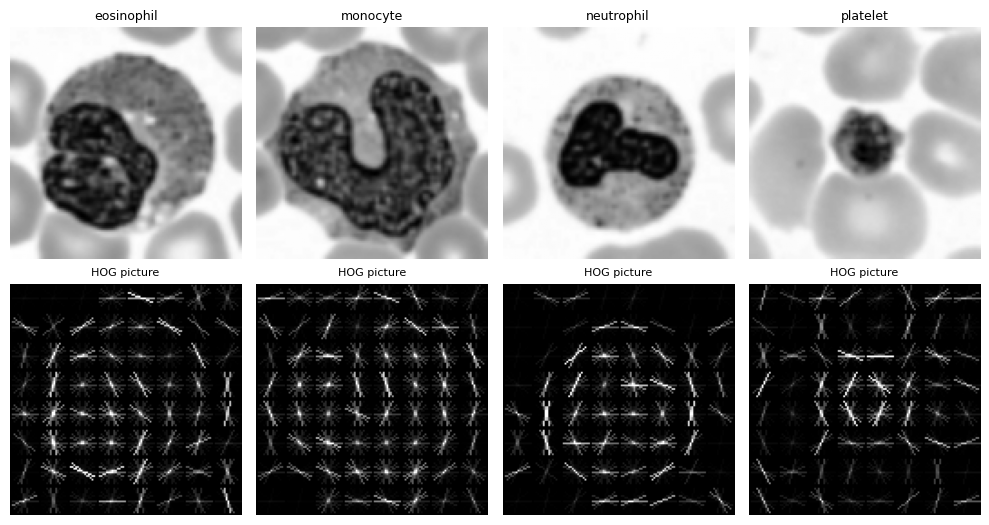

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5.4))
for k, name in enumerate(CLASS_NAMES):
    i = np.where(y_tr == k)[0][0]
    _, hog_img = hog(G_tr[i], orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, np.percentile(hog_img, 99.5) + 1e-9))
    axes[0, k].imshow(G_tr[i], cmap="gray"); axes[0, k].set_title(name, fontsize=9)
    axes[1, k].imshow(hog_img, cmap="gray"); axes[1, k].set_title("HOG picture", fontsize=8)
    axes[0, k].axis("off"); axes[1, k].axis("off")
plt.tight_layout()
save_show(fig, "q2_hog_pictures.png")


## Q2 (c) Train the SVM — choose C on the validation set
`LinearSVC` is trained on the 400 training images for each C in {0.1, 1, 10}. The C with the **highest validation accuracy** is chosen
(if two values tie, the higher macro-F1 wins; if still tied, the smaller C — the simpler model — is kept). The test set is not used.

C values tried on the validation set:


,C,validation accuracy,validation macro-F1
0,0.1,0.8083,0.8056
1,1.0,0.7667,0.7632
2,10.0,0.7750,0.7737


Chosen C = 0.1
Validation accuracy = 0.8083   |   validation macro-F1 = 0.8056
Confusion matrix (validation):


,pred eosinophil,pred monocyte,pred neutrophil,pred platelet
true eosinophil,19,5,6,0
true monocyte,2,27,1,0
true neutrophil,5,2,22,1
true platelet,0,0,1,29


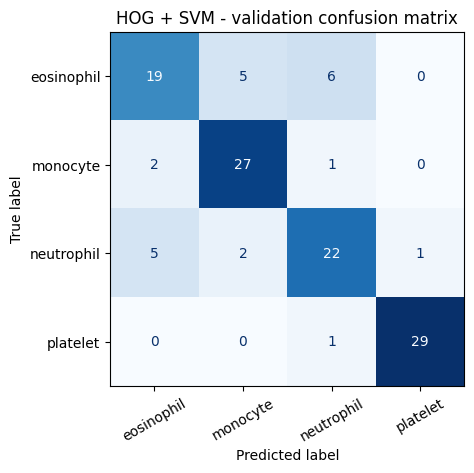

In [10]:
C_GRID = [0.1, 1, 10]


def choose_C(Xtr, ytr, Xva, yva):
    rows, best = [], None
    for C in C_GRID:
        clf = LinearSVC(C=C, dual=True, max_iter=100000, random_state=SEED).fit(Xtr, ytr)
        pred = clf.predict(Xva)
        acc, f1 = accuracy_score(yva, pred), f1_score(yva, pred, average="macro")
        rows.append({"C": C, "validation accuracy": round(acc, 4), "validation macro-F1": round(f1, 4)})
        if best is None or (acc, f1) > (best["acc"], best["f1"]):          # strict '>' keeps the smaller C on ties
            best = {"C": C, "acc": acc, "f1": f1, "clf": clf, "pred": pred}
    return best, pd.DataFrame(rows)


def report(best, table, y_val, title, fname, key):
    print(f"C values tried on the validation set:")
    display(table)
    print(f"Chosen C = {best['C']}")
    print(f"Validation accuracy = {best['acc']:.4f}   |   validation macro-F1 = {best['f1']:.4f}")
    cm = confusion_matrix(y_val, best["pred"], labels=range(4))
    cm_df = pd.DataFrame(cm, index=[f"true {n}" for n in CLASS_NAMES], columns=[f"pred {n}" for n in CLASS_NAMES])
    print("Confusion matrix (validation):")
    display(cm_df)
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
    ax.set_title(title)
    save_show(fig, fname)
    R[key] = {"table": table, "C": best["C"], "acc": best["acc"], "f1": best["f1"], "cm": cm, "cm_df": cm_df}


hog_best, hog_table = choose_C(H_tr, y_tr, H_va, y_va)
report(hog_best, hog_table, y_va, "HOG + SVM - validation confusion matrix", "q2_confusion_hog.png", "hog_val")
hog_model = hog_best["clf"]          # trained on the training set only, with the chosen C


# Q3. SIFT + SVM (7 marks)

## Q3 (a) Normal SIFT detection on the training images
`cv2.SIFT_create().detectAndCompute(image, None)` finds keypoints wherever the image is "interesting", so the number of keypoints is different for every image.

Keypoints per training image (400 images):
  average = 70.58
  minimum = 7
  maximum = 181
  images with ZERO keypoints = 0


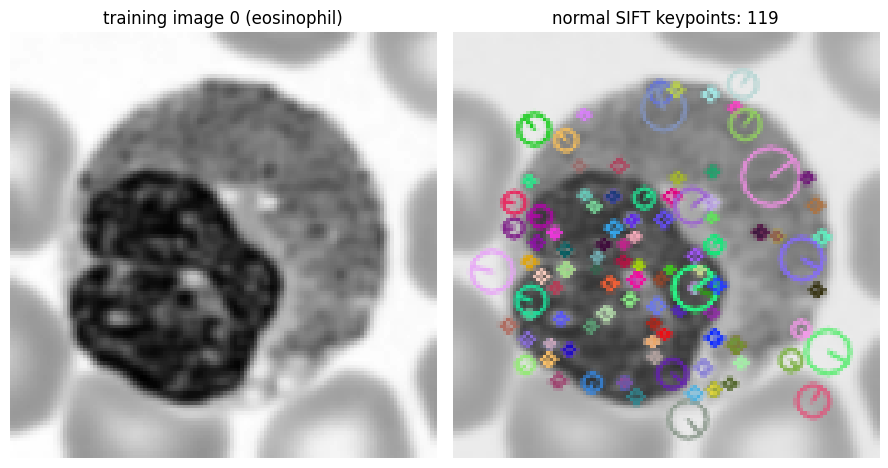

In [11]:
sift = cv2.SIFT_create()

kp_counts = []
for im in G_tr:
    kps, des = sift.detectAndCompute(im, None)         # des is None when no keypoint is found
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

sift_stats = {"average": float(kp_counts.mean()), "min": int(kp_counts.min()),
              "max": int(kp_counts.max()), "zero": int((kp_counts == 0).sum())}
R["sift_stats"] = sift_stats
print(f"Keypoints per training image ({len(kp_counts)} images):")
print(f"  average = {sift_stats['average']:.2f}")
print(f"  minimum = {sift_stats['min']}")
print(f"  maximum = {sift_stats['max']}")
print(f"  images with ZERO keypoints = {sift_stats['zero']}")

i0 = 0
kps0, _ = sift.detectAndCompute(G_tr[i0], None)
vis = cv2.drawKeypoints(G_tr[i0], kps0, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
axes[0].imshow(G_tr[i0], cmap="gray"); axes[0].set_title(f"training image {i0} ({CLASS_NAMES[y_tr[i0]]})"); axes[0].axis("off")
axes[1].imshow(vis); axes[1].set_title(f"normal SIFT keypoints: {len(kps0)}"); axes[1].axis("off")
plt.tight_layout()
save_show(fig, "q3_sift_keypoints.png")


**Why is a different number of keypoints per image a problem for an SVM?**
An SVM needs every image to be one feature vector of the **same fixed length**, but normal SIFT gives each image a different number of 128-number descriptors (even none at all), at different positions, so the descriptors cannot be stacked into one fixed-size feature matrix.

## Q3 (b) Fix: SIFT descriptors on a fixed grid of keypoints
Instead of letting SIFT choose the keypoints, I place keypoints on a **regular 4 × 4 grid** over the 128 × 128 image (keypoint size 32), compute the SIFT descriptor at **every** grid point with `sift.compute`, and join the descriptors into one vector.
Every image now has exactly the same number of keypoints at the same positions → fixed-length features.

Number of grid keypoints: 16
SIFT feature matrix  train: (400, 2048)  validation: (120, 2048)
SIFT feature length (from the code)   : 2048
Hand formula: 4 x 4 = 16 grid points x 128 = 2048


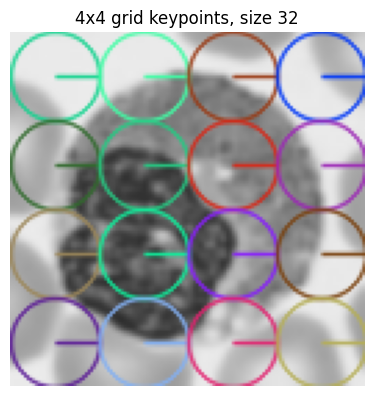

In [12]:
GRID_KP_SIZE = 32


def grid_keypoints(grid=SIFT_GRID, img_size=128, size=GRID_KP_SIZE):
    step = img_size / grid
    centres = (np.arange(grid) + 0.5) * step                       # e.g. grid 4 -> 16, 48, 80, 112
    # angle = 0: the orientation is NOT re-estimated, the descriptor is computed "upright" at every grid point
    return [cv2.KeyPoint(float(x), float(y), float(size), 0.0) for y in centres for x in centres]


GRID_KPS = grid_keypoints()


def sift_grid_vec(img):
    kps, des = sift.compute(img, GRID_KPS)                         # one 128-number descriptor per grid point
    assert des is not None and des.shape == (SIFT_GRID ** 2, 128), des.shape if des is not None else None
    des = des / (np.linalg.norm(des, axis=1, keepdims=True) + 1e-12)   # unit length per descriptor (see note below)
    return des.reshape(-1)                                          # join all descriptors into ONE vector


def sift_matrix(images):
    return np.array([sift_grid_vec(im) for im in images], dtype=np.float32)


S_tr = sift_matrix(G_tr)
S_va = sift_matrix(G_va)

sift_len = S_tr.shape[1]
print("Number of grid keypoints:", len(GRID_KPS))
print("SIFT feature matrix  train:", S_tr.shape, " validation:", S_va.shape)
print("SIFT feature length (from the code)   :", sift_len)
print(f"Hand formula: {SIFT_GRID} x {SIFT_GRID} = {SIFT_GRID ** 2} grid points x 128 = {SIFT_GRID ** 2 * 128}")
assert sift_len == SIFT_GRID ** 2 * 128
R["sift_len"] = sift_len

# picture of the grid
vis = cv2.drawKeypoints(G_tr[0], GRID_KPS, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
fig, ax = plt.subplots(figsize=(4.6, 4.6)); ax.imshow(vis); ax.axis("off")
ax.set_title(f"{SIFT_GRID}x{SIFT_GRID} grid keypoints, size {GRID_KP_SIZE}")
save_show(fig, "q3_grid_keypoints.png")


**Hand calculation of the SIFT feature length** (4 × 4 grid):

1. Grid points = 4 × 4 = **16 keypoints**.
2. Every SIFT descriptor has **128** numbers (4 × 4 spatial cells × 8 orientation bins = 128).
3. Feature length = 16 × 128 = **2048**.

*Note on scaling:* OpenCV returns SIFT descriptors with length ≈ 512 whereas HOG blocks have length 1. To keep both feature types on a comparable scale (so the same C range {0.1, 1, 10} means the same thing for both models), every 128-number descriptor is divided by its own length (unit length) before the descriptors are joined. This does not change the feature length.

## Q3 (c) Train the SVM — choose C on the validation set

C values tried on the validation set:


,C,validation accuracy,validation macro-F1
0,0.1,0.8083,0.8065
1,1.0,0.8250,0.8265
2,10.0,0.8167,0.8187


Chosen C = 1
Validation accuracy = 0.8250   |   validation macro-F1 = 0.8265
Confusion matrix (validation):


,pred eosinophil,pred monocyte,pred neutrophil,pred platelet
true eosinophil,21,6,3,0
true monocyte,7,23,0,0
true neutrophil,4,1,25,0
true platelet,0,0,0,30


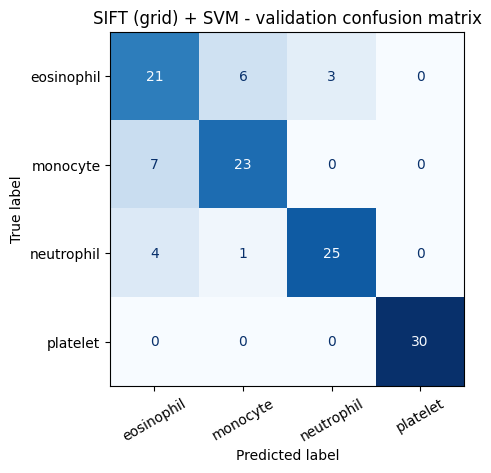

In [13]:
sift_best, sift_table = choose_C(S_tr, y_tr, S_va, y_va)
report(sift_best, sift_table, y_va, "SIFT (grid) + SVM - validation confusion matrix", "q3_confusion_sift.png", "sift_val")
sift_model = sift_best["clf"]        # trained on the training set only, with the chosen C


# Q4. Robustness (6 marks)

## Q4 (a) Prediction — written BEFORE running the robustness test
*(This is my own prediction. It is written before the test-set results exist; the code below checks it against the real numbers.)*

- **Rotation by 20°:** I think **HOG + SVM will lose more accuracy**. HOG's 9 orientation bins are 20° wide (180° / 9), so a 20° rotation pushes the gradient strength of every edge into the neighbouring orientation bin and the feature vector changes a lot. The SIFT descriptor spreads each gradient smoothly over neighbouring orientation/position bins (8 bins of 45°, with interpolation and Gaussian weighting), so it should change more gently.
- **Gaussian noise (σ = 0.05):** I think **HOG + SVM will lose more accuracy**. HOG takes gradients directly from the raw pixels, so pixel noise creates many random gradients that the block normalisation then amplifies, whereas SIFT first smooths the image with a Gaussian blur, which removes much of the pixel noise before the gradients are computed.

In [14]:
# the same prediction as above, written as data so the code can check it later (edit BOTH places if you change it)
PREDICTION = {"rotation": "HOG + SVM", "noise": "HOG + SVM"}     # the model I expect to lose MORE accuracy
print("My prediction (model expected to lose more accuracy):", PREDICTION)


My prediction (model expected to lose more accuracy): {'rotation': 'HOG + SVM', 'noise': 'HOG + SVM'}


## Q4 (b) Evaluation of the frozen models on the test set
Both models are **frozen** (trained on the training set with the C chosen on validation; nothing is re-trained or re-tuned). On the test set I evaluate three cases. The change is applied to the **prepared 128 × 128 gray images, before feature extraction**, and both models receive exactly the same changed images:
- **clean** — no change;
- **rotated** — rotated by 20° about the image centre (`cv2.warpAffine`, border pixels filled by reflecting the image so no artificial black corners appear);
- **noisy** — Gaussian noise with σ = 0.05 added to the image scaled to [0, 1] (clipped to [0, 1], then back to 0–255).

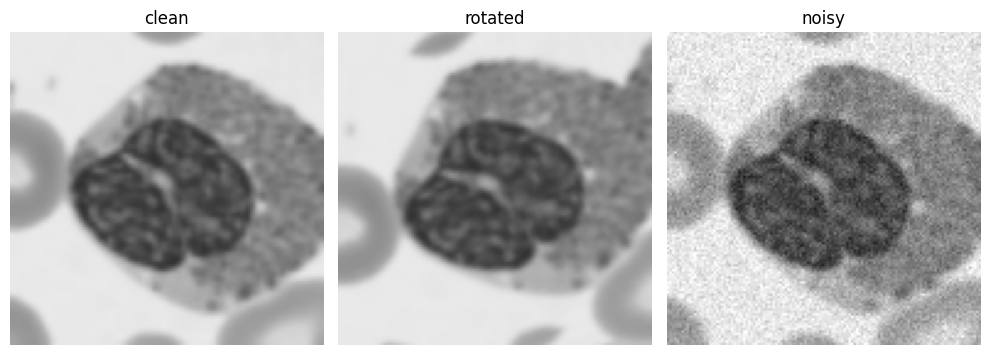

Test set: 120 images (1 image = 0.83 percentage points)



,Model,Clean accuracy,Rotated accuracy,Noisy accuracy
0,HOG + SVM,71.67%,70.83%,28.33%
1,SIFT + SVM,74.17%,74.17%,75.83%


,Model,Drop under rotation (points),Drop under noise (points)
0,HOG + SVM,0.83,43.33
1,SIFT + SVM,0.00,-1.67


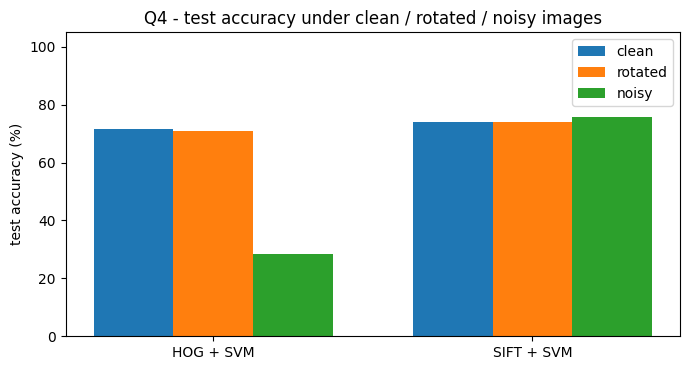

In [15]:
def rotate_img(img, angle=20):
    M = cv2.getRotationMatrix2D((img.shape[1] / 2, img.shape[0] / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REFLECT_101)


def noisy_img(img, sigma, rs):
    f = img.astype(np.float32) / 255.0                                 # scale to 0..1
    f = np.clip(f + rs.normal(0.0, sigma, f.shape), 0.0, 1.0)          # add N(0, sigma^2) noise
    return np.round(f * 255.0).astype(np.uint8)


rs_noise = np.random.RandomState(SEED)                                  # fixed seed -> same noise every run
test_sets = {
    "clean":   G_te,
    "rotated": np.stack([rotate_img(im, 20) for im in G_te]),
    "noisy":   np.stack([noisy_img(im, 0.05, rs_noise) for im in G_te]),
}

# look at what the changes do (sanity check)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, (name, arr) in zip(axes, test_sets.items()):
    ax.imshow(arr[0], cmap="gray", vmin=0, vmax=255); ax.set_title(name); ax.axis("off")
plt.tight_layout()
save_show(fig, "q4_corruption_examples.png")

features = {"HOG + SVM": (hog_model, hog_matrix), "SIFT + SVM": (sift_model, sift_matrix)}
acc = {}
for model_name, (model, featurize) in features.items():
    for case, images in test_sets.items():
        pred = model.predict(featurize(images))
        acc[(model_name, case)] = accuracy_score(y_te, pred)

robust_df = pd.DataFrame({
    "Model": list(features),
    "Clean accuracy":   [f"{100 * acc[(m, 'clean')]:.2f}%" for m in features],
    "Rotated accuracy": [f"{100 * acc[(m, 'rotated')]:.2f}%" for m in features],
    "Noisy accuracy":   [f"{100 * acc[(m, 'noisy')]:.2f}%" for m in features],
})
print(f"Test set: {len(y_te)} images (1 image = {100 / len(y_te):.2f} percentage points)\n")
display(robust_df)

drop_df = pd.DataFrame({
    "Model": list(features),
    "Drop under rotation (points)": [round(100 * (acc[(m, 'clean')] - acc[(m, 'rotated')]), 2) for m in features],
    "Drop under noise (points)":    [round(100 * (acc[(m, 'clean')] - acc[(m, 'noisy')]), 2) for m in features],
})
display(drop_df)
R["robust_df"], R["drop_df"], R["acc"] = robust_df, drop_df, acc

fig, ax = plt.subplots(figsize=(7, 3.8))
w = 0.25
for k, case in enumerate(["clean", "rotated", "noisy"]):
    ax.bar(np.arange(2) + (k - 1) * w, [100 * acc[(m, case)] for m in features], w, label=case)
ax.set_xticks(range(2)); ax.set_xticklabels(list(features)); ax.set_ylabel("test accuracy (%)")
ax.set_ylim(0, 105); ax.legend(); ax.set_title("Q4 - test accuracy under clean / rotated / noisy images")
plt.tight_layout()
save_show(fig, "q4_accuracy_bars.png")


## Q4 (c) Was my prediction correct?

In [16]:
def lost_more(case):
    d_hog = acc[("HOG + SVM", "clean")] - acc[("HOG + SVM", case)]
    d_sift = acc[("SIFT + SVM", "clean")] - acc[("SIFT + SVM", case)]
    if abs(d_hog - d_sift) < 1e-12:
        return "equal", 100 * d_hog, 100 * d_sift
    return ("HOG + SVM" if d_hog > d_sift else "SIFT + SVM"), 100 * d_hog, 100 * d_sift


sentences = []
verdicts = []
for case, label in [("rotated", "rotation"), ("noisy", "noise")]:
    who, d_h, d_s = lost_more(case)
    ok = (who == PREDICTION[label])
    verdicts.append(ok)
    outcome = ("both models lost the same amount" if who == "equal"
               else f"{who} lost more accuracy")
    sentences.append(f"Under {label}, HOG + SVM changed from {100 * acc[('HOG + SVM', 'clean')]:.2f}% to "
                     f"{100 * acc[('HOG + SVM', case)]:.2f}% (drop {d_h:.2f} points) and SIFT + SVM from "
                     f"{100 * acc[('SIFT + SVM', 'clean')]:.2f}% to {100 * acc[('SIFT + SVM', case)]:.2f}% "
                     f"(drop {d_s:.2f} points), so {outcome}.")
summary = ("My prediction was correct for both rotation and noise." if all(verdicts) else
           "My prediction was wrong for both rotation and noise." if not any(verdicts) else
           "My prediction was correct for " + ("rotation" if verdicts[0] else "noise") +
           " but wrong for " + ("noise" if verdicts[0] else "rotation") + ".")
sentences.append(f"{summary} (I predicted {PREDICTION['rotation']} for rotation and {PREDICTION['noise']} for noise; "
                 f"with only {len(y_te)} test images, one image is {100 / len(y_te):.2f} points, so small gaps should be read with care.)")

for s in sentences:
    print("-", s)
R["q4_sentences"] = sentences


- Under rotation, HOG + SVM changed from 71.67% to 70.83% (drop 0.83 points) and SIFT + SVM from 74.17% to 74.17% (drop 0.00 points), so HOG + SVM lost more accuracy.
- Under noise, HOG + SVM changed from 71.67% to 28.33% (drop 43.33 points) and SIFT + SVM from 74.17% to 75.83% (drop -1.67 points), so HOG + SVM lost more accuracy.
- My prediction was correct for both rotation and noise. (I predicted HOG + SVM for rotation and HOG + SVM for noise; with only 120 test images, one image is 0.83 points, so small gaps should be read with care.)


*(The three sentences above are generated from the table's numbers. In the viva: say which model lost more, by how many points, and give the reason from the Q4 (a) text; if the prediction was wrong, say honestly which assumption was wrong.)*

# Q5. Short answers and AI log (3 marks)

## Q5 (a) and (b)
**(a) Why does HOG use block normalisation?**
The size of the gradients in a cell depends on lighting and contrast, so the same edge can give a big or a small histogram just because the picture is brighter or darker. HOG groups neighbouring cells into overlapping blocks and normalises each block's histogram (here L2-Hys), which makes the descriptor much less sensitive to illumination and contrast changes, and every cell is normalised several times in different blocks, which usually improves accuracy.

**(b) Why is it wrong to choose C using the test set?**
The test set is only there to measure how well the finished model works on completely unseen data. If C is chosen by looking at test accuracy, the test images have influenced the model (information leakage), so the reported test accuracy becomes too optimistic and no longer an honest estimate. C must be chosen on the validation set, and the test set used only once at the end.

## Q5 (c) Which two classes were confused most?

In [17]:
PAIR_REASON = {
    frozenset(["eosinophil", "neutrophil"]): "both are granulocytes of similar size with a segmented (lobed) nucleus; the main difference is the colour of the granules (red-orange for eosinophils, pale for neutrophils), and grayscale throws that colour away.",
    frozenset(["eosinophil", "monocyte"]): "both are large round cells with purple nuclei; they differ mostly by granule/cytoplasm colour (orange granules vs blue-grey cytoplasm), which becomes similar gray levels in grayscale.",
    frozenset(["monocyte", "neutrophil"]): "both are large white cells with a purple nucleus; the kidney-shaped nucleus of the monocyte versus the lobed nucleus of the neutrophil is a subtle shape difference at this low resolution (upscaled to 128x128), and the cytoplasm colour cue is lost in grayscale.",
    frozenset(["eosinophil", "platelet"]): "a platelet is a tiny purple fragment while an eosinophil is a large cell, so size should separate them; in grayscale a platelet looks like a dark blob similar to a nucleus lobe, and colour (purple vs orange granules) is lost.",
    frozenset(["monocyte", "platelet"]): "platelets are tiny fragments and monocytes are large cells; confusion can happen when the cell fills little of the image, since in grayscale the purple stain of both becomes similar dark gray.",
    frozenset(["neutrophil", "platelet"]): "platelets are small purple fragments and neutrophils have dark purple nucleus lobes; in grayscale both appear as dark blobs on a light background, and the colour that separates them is lost.",
}

pairs = []
for i in range(4):
    for j in range(i + 1, 4):
        e_hog = R["hog_val"]["cm"][i, j] + R["hog_val"]["cm"][j, i]
        e_sift = R["sift_val"]["cm"][i, j] + R["sift_val"]["cm"][j, i]
        pairs.append({"class pair": f"{CLASS_NAMES[i]} - {CLASS_NAMES[j]}", "HOG errors": int(e_hog),
                      "SIFT errors": int(e_sift), "total errors": int(e_hog + e_sift), "_set": frozenset([CLASS_NAMES[i], CLASS_NAMES[j]])})
pair_df = pd.DataFrame(pairs).sort_values("total errors", ascending=False).reset_index(drop=True)
print("Errors between each pair of classes (validation set, both directions counted):")
display(pair_df.drop(columns="_set"))

top = pair_df.iloc[0]
if top["total errors"] == 0:
    pair_text = "No two classes were confused on the validation set."
else:
    pair_text = (f"The two classes confused most were **{top['class pair']}** ({top['HOG errors']} errors for HOG and "
                 f"{top['SIFT errors']} for SIFT on the validation set). Why grayscale makes this harder: {PAIR_REASON[top['_set']]}")
display(Markdown(pair_text))
R["pair_text"] = pair_text


Errors between each pair of classes (validation set, both directions counted):


,class pair,HOG errors,SIFT errors,total errors
0,eosinophil - monocyte,7,13,20
1,eosinophil - neutrophil,11,7,18
2,monocyte - neutrophil,3,1,4
3,neutrophil - platelet,2,0,2
4,eosinophil - platelet,0,0,0
5,monocyte - platelet,0,0,0


The two classes confused most were **eosinophil - monocyte** (7 errors for HOG and 13 for SIFT on the validation set). Why grayscale makes this harder: both are large round cells with purple nuclei; they differ mostly by granule/cytoplasm colour (orange granules vs blue-grey cytoplasm), which becomes similar gray levels in grayscale.

## Q5 (d) AI log

In [18]:
# EDIT this table so it describes what YOU really did (the exam gives marks for honest checking, not for this template).
AI_LOG = pd.DataFrame([
    {"Prompt (one line)": "Build HOG+SVM and SIFT+SVM for BloodMNIST classes 1,5,6,7, seed 11, HOG cell 16, SIFT 4x4 grid, with a rotation/noise test.",
     "What I changed": "[EDIT: e.g. what you changed or added after reading the code]",
     "How I checked it was correct": "Printed the shapes/class counts of every split; asserted that the HOG and SIFT feature lengths equal my hand calculations (1764 and 2048); looked at the example grid, HOG pictures, keypoint pictures and the rotated/noisy examples."},
])
display(AI_LOG)
if "[EDIT" in AI_LOG.iloc[0]["What I changed"]:
    print("REMINDER: replace the [EDIT ...] text in the AI log with what you really changed.")
R["ai_log"] = AI_LOG


,Prompt (one line),What I changed,How I checked it was correct
0,Build HOG+SVM and SIFT+SVM for BloodMNIST clas...,[EDIT: e.g. what you changed or added after re...,Printed the shapes/class counts of every split...


REMINDER: replace the [EDIT ...] text in the AI log with what you really changed.


In [19]:
# Final self-check against the exam rules (every line should say PASS)
checks = [
    ("Seed = last two digits of the registration number",          SEED == int(REG_NO[-2:])),
    ("HOG cell: even last digit -> 8, odd -> 16",                  HOG_CELL == (8 if int(REG_NO[-1]) % 2 == 0 else 16)),
    ("SIFT grid: last digit 0-4 -> 4, 5-9 -> 6",                   SIFT_GRID == (4 if int(REG_NO[-1]) <= 4 else 6)),
    ("Exactly 4 classes, 100/30/30 images per class",              all((y_tr == k).sum() == 100 and (y_va == k).sum() == 30 and (y_te == k).sum() == 30 for k in range(4))),
    ("All prepared images are 128x128 grayscale",                  G_tr.shape[1:] == G_va.shape[1:] == G_te.shape[1:] == (128, 128)),
    ("HOG length matches the hand calculation",                    R["hog_len"] == (128 // HOG_CELL - 1) ** 2 * 36),
    ("SIFT length = grid points x 128",                            R["sift_len"] == SIFT_GRID ** 2 * 128),
    ("Grid keypoints have size 32",                                all(k.size == 32 for k in GRID_KPS) and len(GRID_KPS) == SIFT_GRID ** 2),
    ("C chosen from {0.1, 1, 10} for both models",                 R["hog_val"]["C"] in C_GRID and R["sift_val"]["C"] in C_GRID),
    ("Robustness table has 2 models x 3 cases",                    len(R["acc"]) == 6),
]
for text, ok in checks:
    print("PASS" if ok else "FAIL", "-", text)
assert all(ok for _, ok in checks), "one of the checks failed - read the FAIL lines above"


PASS - Seed = last two digits of the registration number
PASS - HOG cell: even last digit -> 8, odd -> 16
PASS - SIFT grid: last digit 0-4 -> 4, 5-9 -> 6
PASS - Exactly 4 classes, 100/30/30 images per class
PASS - All prepared images are 128x128 grayscale
PASS - HOG length matches the hand calculation
PASS - SIFT length = grid points x 128
PASS - Grid keypoints have size 32
PASS - C chosen from {0.1, 1, 10} for both models
PASS - Robustness table has 2 models x 3 cases


# Results file for GitHub (all outputs visible)
This cell writes `labmid_outputs/LabMid_results.md` (all tables and the answers above, with the saved pictures linked). Upload the whole `labmid_outputs` folder to GitHub so the pictures show up.
Also export the executed notebook as PDF (Colab: *File → Print → Save as PDF*).

In [20]:
def md_table(df):
    df = df.reset_index(drop=True)
    head = "| " + " | ".join(str(c) for c in df.columns) + " |"
    sep = "|" + "|".join(["---"] * len(df.columns)) + "|"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in df.values]
    return "\n".join([head, sep] + body)


def val_block(key, title):
    r = R[key]
    return (f"{title}\n\n{md_table(r['table'])}\n\nChosen C = **{r['C']}** — validation accuracy = **{r['acc']:.4f}**, "
            f"validation macro-F1 = **{r['f1']:.4f}**\n\nConfusion matrix (validation set):\n\n"
            f"{md_table(r['cm_df'].reset_index().rename(columns={'index': ''}))}\n")


s = R["sift_stats"]
md_text = f"""# Lab Mid Exam — HOG vs SIFT on Blood-Cell Images

**Registration number:** {REG_NO} · **Seed:** {SEED} · **HOG cell:** {HOG_CELL}x{HOG_CELL} · **SIFT grid:** {SIFT_GRID}x{SIFT_GRID} ({SIFT_GRID ** 2} keypoints)

## Q1. Data setup
{md_table(R['q1_counts'].astype(str))}

![examples](q1_examples.png)

![prepared](q1_prepared.png)

## Q2. HOG + SVM
HOG feature length (printed by the code): **{R['hog_len']}**.
Hand calculation: 128/{HOG_CELL} = {128 // HOG_CELL} cells per side; blocks per side = {128 // HOG_CELL} − 2 + 1 = {128 // HOG_CELL - 1}; {(128 // HOG_CELL - 1) ** 2} blocks × (2×2×9 = 36) = **{R['hog_len']}**.

![hog pictures](q2_hog_pictures.png)

{val_block('hog_val', 'HOG + LinearSVC, C chosen on the validation set:')}
![hog confusion](q2_confusion_hog.png)

## Q3. SIFT + SVM
Normal SIFT keypoints per training image: average **{s['average']:.2f}**, minimum **{s['min']}**, maximum **{s['max']}**, images with zero keypoints: **{s['zero']}**.

![sift keypoints](q3_sift_keypoints.png)

A different number of keypoints per image is a problem because an SVM needs every image as a feature vector of the same fixed length, but normal SIFT returns a different number of 128-number descriptors (even none) at different positions for each image.

Fixed grid: {SIFT_GRID}×{SIFT_GRID} = {SIFT_GRID ** 2} keypoints (size 32); feature length = {SIFT_GRID ** 2} × 128 = **{R['sift_len']}** (printed by the code).

![grid keypoints](q3_grid_keypoints.png)

{val_block('sift_val', 'SIFT (grid) + LinearSVC, C chosen on the validation set:')}
![sift confusion](q3_confusion_sift.png)

## Q4. Robustness (test set, frozen models)
**Prediction written before running:** {PREDICTION}.

{md_table(R['robust_df'])}

{md_table(R['drop_df'])}

![corruption examples](q4_corruption_examples.png)

![accuracy bars](q4_accuracy_bars.png)

{chr(10).join('- ' + t for t in R['q4_sentences'])}

## Q5. Short answers and AI log
**(a) Why block normalisation?** HOG cell histograms depend on lighting/contrast; normalising each overlapping block (L2-Hys) makes the descriptor much less sensitive to illumination and contrast changes and normalises each cell several times.

**(b) Why not choose C on the test set?** It leaks test information into the model, so the test accuracy becomes optimistic; C must be chosen on validation and the test set used once at the end.

**(c) Most confused classes.** {R['pair_text']}

**(d) AI log**

{md_table(R['ai_log'])}
"""
path = os.path.join(OUT, "LabMid_results.md")
with open(path, "w", encoding="utf-8") as fh:
    fh.write(md_text)
print("Saved", path, "-", len(md_text.splitlines()), "lines")
print("Pictures saved in", OUT, ":", sorted(f for f in os.listdir(OUT) if f.endswith(".png")))


Saved labmid_outputs/LabMid_results.md - 107 lines
Pictures saved in labmid_outputs : ['q1_examples.png', 'q1_prepared.png', 'q2_confusion_hog.png', 'q2_hog_pictures.png', 'q3_confusion_sift.png', 'q3_grid_keypoints.png', 'q3_sift_keypoints.png', 'q4_accuracy_bars.png', 'q4_corruption_examples.png']


In [21]:
# (optional) download everything as one zip - works in Google Colab only
import shutil
try:
    from google.colab import files
    shutil.make_archive("labmid_outputs", "zip", OUT)
    files.download("labmid_outputs.zip")
except ImportError:
    print("Not in Colab - the files are in the folder:", OUT)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>